# Modeling

## Setup Imports

In [27]:
import sys
from pathlib import Path
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

import matplotlib.pyplot as plt
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

import importlib
import models

importlib.reload(models)
from evaluation import (
    rmse_from_predictions,
    mae_from_predictions,
    evaluate_matrix_model,
    evaluate_factor_model
)
from preprocessing import build_rating_matrix
from models import (
    hard_thresholding_model,
    soft_thresholding_model,
    gradient_descent,
    sgd,
    als_model,
    als_sparse,
    _add_global_mean_to_factors,
)
from als import als_model_numba
from gd_sparce_numba import gradient_descent_numba
from sgd import sgd_numba

import matplotlib.pyplot as plt

## Load processed data

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

DATASET_NAME = "ml-latest-small"
# DATASET_NAME = "ml-1m"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / DATASET_NAME

print("Dataset:", DATASET_NAME)
print("Processed dir:", PROCESSED_DIR)

if DATASET_NAME == "ml-latest":
    raise ValueError(
        "03_modeling.ipynb uses dense matrix models. "
        "Use ml-latest-small or ml-1m here. "
        "For ml-latest use sparse experiments instead."
    )

required_files = [
    "train_ratings.csv",
    "test_ratings.csv",
    "R_train.npy",
    "train_mask.npy",
]

missing_files = [file_name for file_name in required_files if not (PROCESSED_DIR / file_name).exists()]

if missing_files:
    raise FileNotFoundError(
        f"Missing processed files for {DATASET_NAME}: {missing_files}. "
        "Run 02_preprocessing.ipynb first."
    )

train_df = pd.read_csv(PROCESSED_DIR / "train_ratings.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test_ratings.csv")

R_train = np.load(PROCESSED_DIR / "R_train.npy")
train_mask = np.load(PROCESSED_DIR / "train_mask.npy")

movies = pd.read_csv(PROCESSED_DIR / "movies.csv")
movies_with_idx = pd.read_csv(PROCESSED_DIR / "movies_with_idx.csv")

print("train_df:", train_df.shape)
print("test_df:", test_df.shape)
print("R_train:", R_train.shape)

print("Dataset:", DATASET_NAME)
print("Processed dir:", PROCESSED_DIR)

Dataset: ml-latest-small
Processed dir: c:\Studies\KU\Data lab\Data-Lab\data\processed\ml-latest-small
train_df: (80668, 6)
test_df: (20168, 6)
R_train: (610, 9724)
Dataset: ml-latest-small
Processed dir: c:\Studies\KU\Data lab\Data-Lab\data\processed\ml-latest-small


## Baseline Model

As a simple baseline, we predict the global mean rating from the training set for every user-movie pair.

In [3]:
global_mean = train_df["rating"].mean()

train_baseline_preds = np.full(
    shape=len(train_df),
    fill_value=global_mean
)

test_baseline_preds = np.full(
    shape=len(test_df),
    fill_value=global_mean
)

baseline_train_rmse = rmse_from_predictions(train_df["rating"].values, train_baseline_preds)
baseline_train_mae = mae_from_predictions(train_df["rating"].values, train_baseline_preds)

baseline_test_rmse = rmse_from_predictions(test_df["rating"].values, test_baseline_preds)
baseline_test_mae = mae_from_predictions(test_df["rating"].values, test_baseline_preds)

print("Global mean:", global_mean)

print("Baseline train RMSE:", baseline_train_rmse)
print("Baseline train MAE:", baseline_train_mae)

print("Baseline test RMSE:", baseline_test_rmse)
print("Baseline test MAE:", baseline_test_mae)

Global mean: 3.502572271532702
Baseline train RMSE: 1.0409394885218028
Baseline train MAE: 0.8260268491189754
Baseline test RMSE: 1.0488405992661316
Baseline test MAE: 0.8315907281547353


## Train-validation split for hyperparameter tuning

In [4]:
from sklearn.model_selection import train_test_split

train_fit_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print("Train fit shape:", train_fit_df.shape)
print("Validation shape:", val_df.shape)

Train fit shape: (64534, 6)
Validation shape: (16134, 6)


In [5]:
n_users, n_movies = R_train.shape

R_fit = build_rating_matrix(
    train_fit_df,
    n_users=n_users,
    n_movies=n_movies
)

fit_mask = R_fit > 0

print("R_fit shape:", R_fit.shape)
print("Observed ratings in R_fit:", fit_mask.sum())
print("Sparsity R_fit:", 1 - fit_mask.mean())

R_fit shape: (610, 9724)
Observed ratings in R_fit: 64534
Sparsity R_fit: 0.9891203781753444


## Validation metric function

In [6]:
def validation_metrics(X):
    val_rmse, val_mae = evaluate_matrix_model(X, val_df)

    return {
        "val_rmse": val_rmse,
        "val_mae": val_mae
    }

def validation_metrics_factor(U, V):
    val_rmse, val_mae = evaluate_factor_model(U, V, val_df)

    return {
        "val_rmse": val_rmse,
        "val_mae": val_mae
    }

# def test_metrics(X):
#     test_rmse, test_mae = evaluate_matrix_model(X, test_df)

#     return {
#         "test_rmse": test_rmse,
#         "test_mae": test_mae
#     }

## Hard Thresholding Model

### Rank and number of Iterations selection for hard thresholding

In [15]:
rank_values = [2, 3, 4]

all_histories = []

for rank in rank_values:
    print(f"Training hard thresholding with rank={rank}")

    X_hat, history_df = hard_thresholding_model(
        R_fit,
        fit_mask,
        rank=rank,
        n_iter=40,
        metrics_fn=validation_metrics
    )

    all_histories.append(history_df)

tuning_results_df = pd.concat(all_histories, ignore_index=True)

display(
    tuning_results_df
    .sort_values("val_rmse")
    .head(10)
)

Training hard thresholding with rank=2
Training hard thresholding with rank=3
Training hard thresholding with rank=4


,iteration,rank,train_rmse,val_rmse,val_mae
39,40,2,0.802177,0.890818,0.689138
38,39,2,0.803467,0.891299,0.689602
37,38,2,0.804798,0.891804,0.690092
36,37,2,0.806171,0.892335,0.690605
35,36,2,0.807588,0.892893,0.691150
34,35,2,0.809052,0.893480,0.691718
33,34,2,0.810566,0.894098,0.692309
32,33,2,0.812132,0.894749,0.692926
31,32,2,0.813753,0.895435,0.693578
30,31,2,0.815434,0.896159,0.694259


As we can see, 2 is clearly the best rank, and the model is still improving after 40 iterations. So we increase the number of iterations to 60, and leave rank 2.

In [16]:
best_rank = 2

X_hat, tuning_results_df = hard_thresholding_model(
    R_fit,
    fit_mask,
    rank=best_rank,
    n_iter=60,
    metrics_fn=validation_metrics
)

display(
    tuning_results_df
    .sort_values("val_rmse")
    .head(10)
)

,iteration,rank,train_rmse,val_rmse,val_mae
59,60,2,0.782669,0.884466,0.683433
58,59,2,0.783431,0.884678,0.683626
57,58,2,0.784211,0.884899,0.683824
56,57,2,0.785008,0.885128,0.684029
55,56,2,0.785823,0.885367,0.684240
54,55,2,0.786658,0.885616,0.684460
53,54,2,0.787513,0.885875,0.684690
52,53,2,0.788388,0.886145,0.684926
51,52,2,0.789286,0.886426,0.685174
50,51,2,0.790206,0.886718,0.685430


As the difference in val_rmse between 40 and 60 iterations is small, we stop here and do not continue to increase the number of iterations due to computational cost

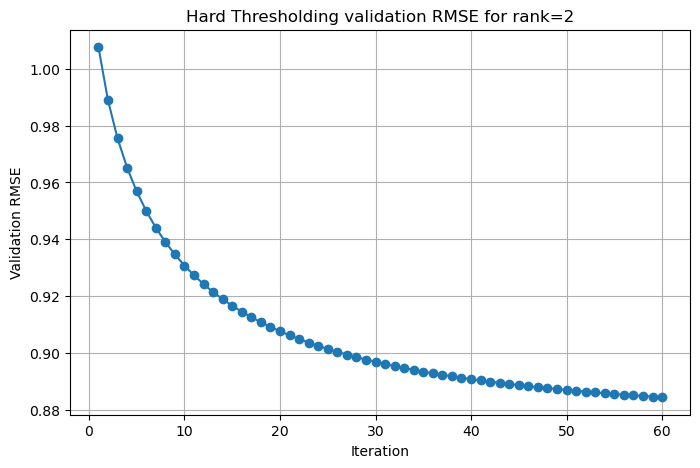

In [17]:
rank_2_history = tuning_results_df[tuning_results_df["rank"] == 2]

plt.figure(figsize=(8, 5))
plt.plot(rank_2_history["iteration"], rank_2_history["val_rmse"], marker="o")
plt.xlabel("Iteration")
plt.ylabel("Validation RMSE")
plt.title("Hard Thresholding validation RMSE for rank=2")
plt.grid(True)
plt.show()

### Full training and test data sets 

In [7]:
best_hard_rank = 2
best_hard_n_iter = 60

X_hard, hard_history = hard_thresholding_model(
    R_train,
    train_mask,
    rank=best_hard_rank,
    n_iter=best_hard_n_iter,
    # metrics_fn=test_metrics
)

hard_test_rmse, hard_test_mae = evaluate_matrix_model(X_hard, test_df)

print("Final rank:", best_hard_rank)
print("Final n_iter:", best_hard_n_iter)
print("Hard Thresholding test RMSE:", hard_test_rmse)
print("Hard Thresholding test MAE:", hard_test_mae)


Final rank: 2
Final n_iter: 60
Hard Thresholding test RMSE: 0.8877206384988603
Hard Thresholding test MAE: 0.6825784740314891


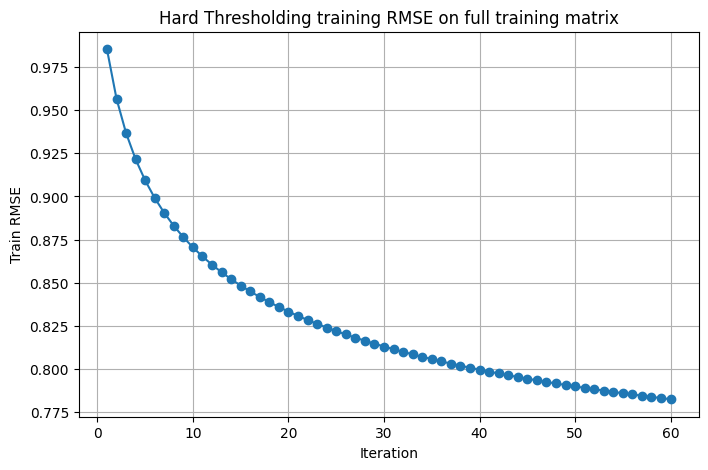

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    hard_history["iteration"],
    hard_history["train_rmse"],
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Train RMSE")
plt.title("Hard Thresholding training RMSE on full training matrix")
plt.grid(True)

plt.show()

## Soft Thresholding 

### Tau and number of iterations search for soft thresholding

In [20]:
tau_values = [5, 10, 20, 40, 80]

all_histories = []

for tau in tau_values:
    print(f"Training soft thresholding with tau={tau}")

    X_hat, history_df = soft_thresholding_model(
        R_fit,
        fit_mask,
        tau=tau,
        n_iter=20,
        metrics_fn=validation_metrics
    )

    all_histories.append(history_df)

soft_tuning_results_df = pd.concat(all_histories, ignore_index=True)

display(
    soft_tuning_results_df
    .sort_values("val_rmse")
    .head(10)
)

Training soft thresholding with tau=5
Training soft thresholding with tau=10
Training soft thresholding with tau=20
Training soft thresholding with tau=40
Training soft thresholding with tau=80


,iteration,tau,train_rmse,val_rmse,val_mae
39,20,10,0.599422,0.898883,0.700410
38,19,10,0.600034,0.900792,0.701991
37,18,10,0.600687,0.902840,0.703704
59,20,20,0.831483,0.903104,0.708159
58,19,20,0.832409,0.904390,0.709133
36,17,10,0.601390,0.905041,0.705562
57,18,20,0.833427,0.905798,0.710226
56,17,20,0.834524,0.907341,0.711439
35,16,10,0.602188,0.907413,0.707574
55,16,20,0.835700,0.909036,0.712781


In [21]:
tau_values = [5, 8, 10, 12, 15]

all_histories = []

for tau in tau_values:
    print(f"Training soft thresholding with tau={tau}")

    X_hat, history_df = soft_thresholding_model(
        R_fit,
        fit_mask,
        tau=tau,
        n_iter=30,
        metrics_fn=validation_metrics
    )

    all_histories.append(history_df)

soft_tuning_results_df = pd.concat(all_histories, ignore_index=True)

display(
    soft_tuning_results_df
    .sort_values("val_rmse")
    .head(10)
)

Training soft thresholding with tau=5
Training soft thresholding with tau=8
Training soft thresholding with tau=10
Training soft thresholding with tau=12
Training soft thresholding with tau=15


,iteration,tau,train_rmse,val_rmse,val_mae
119,30,12,0.664548,0.883474,0.689285
118,29,12,0.664962,0.884378,0.689930
149,30,15,0.743830,0.885059,0.692209
89,30,10,0.594959,0.885270,0.689524
117,28,12,0.665347,0.885335,0.690624
148,29,15,0.744273,0.885822,0.692729
88,29,10,0.595302,0.886292,0.690298
116,27,12,0.665747,0.886351,0.691369
147,28,15,0.744740,0.886638,0.693294
87,28,10,0.595656,0.887374,0.691118


The best tau is around 12. But since the best number of iteration is 30 (the upper bound), we increase their number to 50.

In [22]:
tau_values = [11, 12, 13]

all_histories = []

for tau in tau_values:
    print(f"Training soft thresholding with tau={tau}")

    X_hat, history_df = soft_thresholding_model(
        R_fit,
        fit_mask,
        tau=tau,
        n_iter=50,
        metrics_fn=validation_metrics
    )

    all_histories.append(history_df)

soft_tuning_results_df = pd.concat(all_histories, ignore_index=True)

display(
    soft_tuning_results_df
    .sort_values("val_rmse")
    .head(10)
)

Training soft thresholding with tau=11
Training soft thresholding with tau=12
Training soft thresholding with tau=13


,iteration,tau,train_rmse,val_rmse,val_mae
49,50,11,0.626572,0.872395,0.681203
99,50,12,0.659328,0.872707,0.682168
48,49,11,0.626741,0.872747,0.681420
98,49,12,0.659510,0.873020,0.682349
47,48,11,0.626916,0.873116,0.681649
97,48,12,0.659692,0.873350,0.682540
46,47,11,0.627097,0.873504,0.681895
149,50,13,0.688585,0.873591,0.683576
96,47,12,0.659882,0.873699,0.682746
148,49,13,0.688766,0.873859,0.683719


We continue with tau = 11, but now increase the number of iterations

In [23]:
best_soft_tau = 11

X_hat, soft_tuning_results_df = soft_thresholding_model(
    R_fit,
    fit_mask,
    tau=best_soft_tau,
    n_iter=100,
    metrics_fn=validation_metrics
)

display(
    soft_tuning_results_df
    .sort_values("val_rmse")
    .head(10)
)

,iteration,tau,train_rmse,val_rmse,val_mae
85,86,11,0.623186,0.867321,0.679168
86,87,11,0.623150,0.867323,0.679217
84,85,11,0.623224,0.867325,0.679122
87,88,11,0.623117,0.867329,0.679270
83,84,11,0.623265,0.867334,0.679080
88,89,11,0.623086,0.867342,0.679326
82,83,11,0.623308,0.867349,0.679042
89,90,11,0.623057,0.867359,0.679385
81,82,11,0.623354,0.867370,0.679010
90,91,11,0.623031,0.867381,0.679448


Graphically:

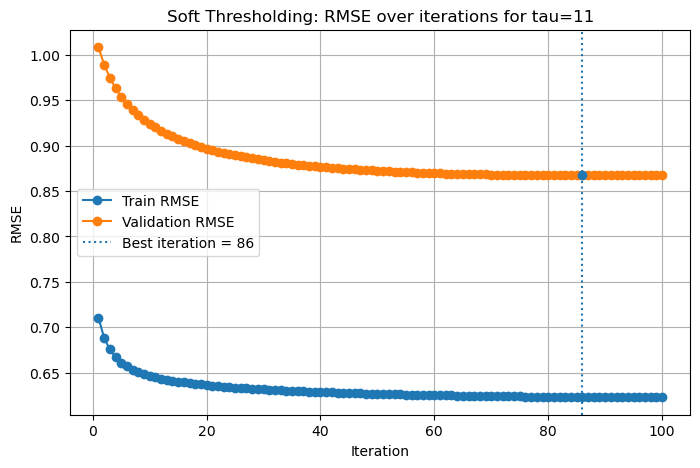

Best tau: 11
Best number of iterations: 86
Best validation RMSE: 0.8673208709206485


In [24]:
best_soft_row = soft_tuning_results_df.loc[
    soft_tuning_results_df["val_rmse"].idxmin()
]

best_soft_n_iter = int(best_soft_row["iteration"])
best_soft_val_rmse = best_soft_row["val_rmse"]

plt.figure(figsize=(8, 5))

plt.plot(
    soft_tuning_results_df["iteration"],
    soft_tuning_results_df["train_rmse"],
    marker="o",
    label="Train RMSE"
)

plt.plot(
    soft_tuning_results_df["iteration"],
    soft_tuning_results_df["val_rmse"],
    marker="o",
    label="Validation RMSE"
)

plt.axvline(
    best_soft_n_iter,
    linestyle=":",
    label=f"Best iteration = {best_soft_n_iter}"
)

plt.scatter(
    best_soft_n_iter,
    best_soft_val_rmse,
    zorder=3
)

plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title(f"Soft Thresholding: RMSE over iterations for tau={best_soft_tau}")
plt.legend()
plt.grid(True)

plt.show()

print("Best tau:", best_soft_tau)
print("Best number of iterations:", best_soft_n_iter)
print("Best validation RMSE:", best_soft_val_rmse)

The best result is 86 iterations and tau = 11. 

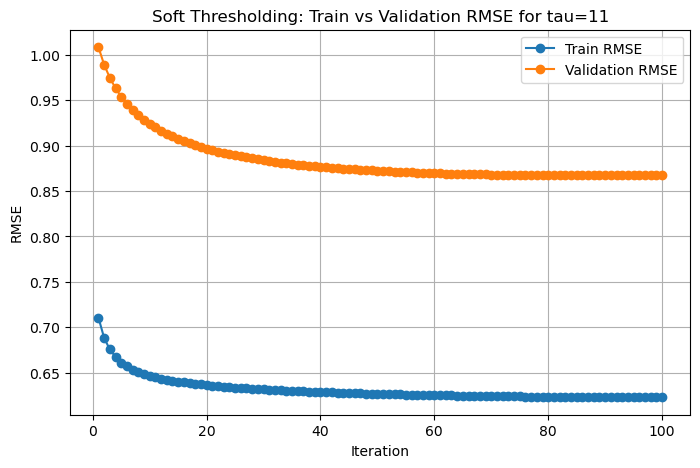

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    soft_tuning_results_df["iteration"],
    soft_tuning_results_df["train_rmse"],
    marker="o",
    label="Train RMSE"
)

plt.plot(
    soft_tuning_results_df["iteration"],
    soft_tuning_results_df["val_rmse"],
    marker="o",
    label="Validation RMSE"
)

plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("Soft Thresholding: Train vs Validation RMSE for tau=11")
plt.legend()
plt.grid(True)

plt.show()

### Full training and test data sets

In [9]:
best_soft_tau = 11
best_soft_n_iter = 86

X_soft, soft_history = soft_thresholding_model(
    R_train,
    train_mask,
    tau=best_soft_tau,
    n_iter=best_soft_n_iter
)

soft_test_rmse, soft_test_mae = evaluate_matrix_model(X_soft, test_df)

print("Final tau:", best_soft_tau)
print("Final n_iter:", best_soft_n_iter)
print("Soft Thresholding test RMSE:", soft_test_rmse)
print("Soft Thresholding test MAE:", soft_test_mae)

# display(soft_history)

Final tau: 11
Final n_iter: 86
Soft Thresholding test RMSE: 0.8702908977602052
Soft Thresholding test MAE: 0.6771797737994913


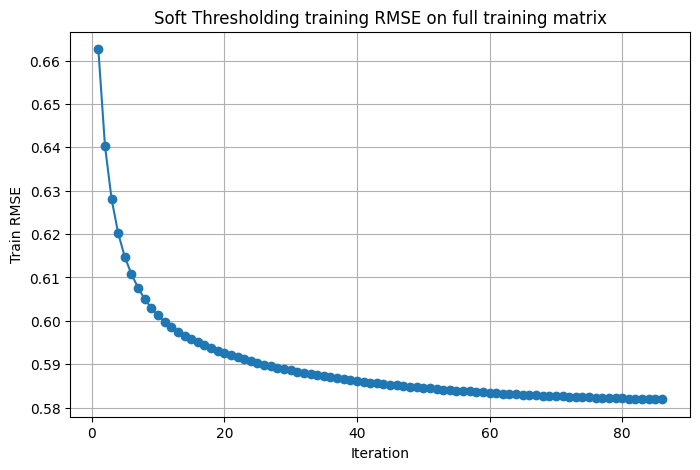

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    soft_history["iteration"],
    soft_history["train_rmse"],
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Train RMSE")
plt.title("Soft Thresholding training RMSE on full training matrix")
plt.grid(True)

plt.show()

## GD


### Parameter search

In [11]:
val_user_idx = val_df["user_idx"].to_numpy(dtype=np.int64)
val_movie_idx = val_df["movie_idx"].to_numpy(dtype=np.int64)
val_ratings = val_df["rating"].to_numpy(dtype=np.float64)


def validation_metrics_gd_numba(U, V, global_mean):
    predictions = (
        global_mean
        + np.sum(
            U[val_user_idx] * V[val_movie_idx],
            axis=1,
        )
    )
    predictions = np.clip(predictions, 0.5, 5.0)

    return {
        "val_rmse": rmse_from_predictions(val_ratings, predictions),
        "val_mae": mae_from_predictions(val_ratings, predictions),
    }


rank_values = [20, 40, 60]
eta_values = [0.002, 0.003, 0.005]
reg_values = [4.0, 6.0, 8.0]

init_scale = 0.05
all_histories = []

for rank in rank_values:
    for eta in eta_values:
        for reg in reg_values:
            print(
                f"Training GD Numba: "
                f"rank={rank}, eta={eta}, reg={reg}"
            )

            U, V, global_mean, history_df = gradient_descent_numba(
                train_fit_df,
                n_users=n_users,
                n_movies=n_movies,
                rank=rank,
                eta=eta,
                reg=reg,
                n_iter=150,
                init_scale=init_scale,
                random_state=42,
                metrics_fn=validation_metrics_gd_numba,
                min_iter=30,
                objective_tol=1e-6,
                patience=8,
            )

            all_histories.append(history_df)

gd_numba_tuning_results_df = pd.concat(
    all_histories,
    ignore_index=True,
)

display(
    gd_numba_tuning_results_df
    .sort_values("val_rmse")
    .head(15)
)

Training GD Numba: rank=20, eta=0.002, reg=4.0
Training GD Numba: rank=20, eta=0.002, reg=6.0
Training GD Numba: rank=20, eta=0.002, reg=8.0
Training GD Numba: rank=20, eta=0.003, reg=4.0
Training GD Numba: rank=20, eta=0.003, reg=6.0
Training GD Numba: rank=20, eta=0.003, reg=8.0
Training GD Numba: rank=20, eta=0.005, reg=4.0
Training GD Numba: rank=20, eta=0.005, reg=6.0
Training GD Numba: rank=20, eta=0.005, reg=8.0
Training GD Numba: rank=40, eta=0.002, reg=4.0
Training GD Numba: rank=40, eta=0.002, reg=6.0
Training GD Numba: rank=40, eta=0.002, reg=8.0
Training GD Numba: rank=40, eta=0.003, reg=4.0
Training GD Numba: rank=40, eta=0.003, reg=6.0
Training GD Numba: rank=40, eta=0.003, reg=8.0
Training GD Numba: rank=40, eta=0.005, reg=4.0
Training GD Numba: rank=40, eta=0.005, reg=6.0
Training GD Numba: rank=40, eta=0.005, reg=8.0
Training GD Numba: rank=60, eta=0.002, reg=4.0
Training GD Numba: rank=60, eta=0.002, reg=6.0
Training GD Numba: rank=60, eta=0.002, reg=8.0
Training GD N

,iteration,rank,eta,reg,init_scale,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse,val_mae
2217,118,40,0.003,8.0,0.05,22295.667957,0.632330,0.632264,0.000704,0.904542,0.701699
2216,117,40,0.003,8.0,0.05,22311.370730,0.633654,0.633588,0.000722,0.904542,0.701703
2218,119,40,0.003,8.0,0.05,22280.364160,0.631029,0.630963,0.000686,0.904545,0.701697
2215,116,40,0.003,8.0,0.05,22327.485824,0.635000,0.634934,0.000740,0.904546,0.701711
2219,120,40,0.003,8.0,0.05,22265.446461,0.629750,0.629683,0.000670,0.904550,0.701699
2214,115,40,0.003,8.0,0.05,22344.027062,0.636370,0.636304,0.000759,0.904552,0.701719
2220,121,40,0.003,8.0,0.05,22250.902437,0.628492,0.628425,0.000653,0.904558,0.701706
2213,114,40,0.003,8.0,0.05,22361.008765,0.637764,0.637698,0.000779,0.904563,0.701730
2221,122,40,0.003,8.0,0.05,22236.720099,0.627256,0.627189,0.000637,0.904569,0.701716
2212,113,40,0.003,8.0,0.05,22378.445768,0.639181,0.639116,0.000800,0.904577,0.701744


In [12]:
config_columns = ["rank", "eta", "reg", "init_scale"]

coarse_best_by_config = (
    gd_numba_tuning_results_df.loc[
        gd_numba_tuning_results_df
        .groupby(config_columns)["val_rmse"]
        .idxmin()
    ]
    .sort_values("val_rmse")
)

display(coarse_best_by_config.head(15))

,iteration,rank,eta,reg,init_scale,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse,val_mae
2217,118,40,0.003,8.0,0.05,22295.667957,0.632330,0.632264,0.000704,0.904542,0.701699
3573,124,60,0.003,8.0,0.05,21965.951412,0.605112,0.605080,0.000541,0.904662,0.702388
2620,71,40,0.005,8.0,0.05,22297.992631,0.632271,0.632204,0.001184,0.904804,0.701897
3974,75,60,0.005,8.0,0.05,21958.662012,0.604150,0.604117,0.000892,0.904897,0.702563
1799,150,40,0.002,8.0,0.05,22648.810644,0.659722,0.659659,0.000748,0.905035,0.702210
3149,150,60,0.002,8.0,0.05,22360.844944,0.638791,0.638754,0.000691,0.905379,0.703186
1639,140,40,0.002,6.0,0.05,19918.257623,0.610549,0.610427,0.001415,0.905919,0.701833
2043,94,40,0.003,6.0,0.05,19900.229779,0.609415,0.609292,0.002106,0.906151,0.702004
2996,147,60,0.002,6.0,0.05,19315.471905,0.571167,0.571099,0.001184,0.906291,0.702776
3397,98,60,0.003,6.0,0.05,19321.176363,0.571498,0.571429,0.001793,0.906513,0.702952


In [13]:
refined_rank_values = [40, 50, 60]
refined_eta_values = [0.003, 0.004, 0.005]
refined_reg_values = [8.0, 10.0, 12.0, 16.0]

refined_init_scale = 0.05
refined_histories = []

for rank in refined_rank_values:
    for eta in refined_eta_values:
        for reg in refined_reg_values:
            print(
                f"Training refined GD Numba: "
                f"rank={rank}, eta={eta}, reg={reg}"
            )

            U, V, global_mean, history_df = gradient_descent_numba(
                train_fit_df,
                n_users=n_users,
                n_movies=n_movies,
                rank=rank,
                eta=eta,
                reg=reg,
                n_iter=160,
                init_scale=refined_init_scale,
                random_state=42,
                metrics_fn=validation_metrics_gd_numba,
                min_iter=30,
                objective_tol=1e-6,
                patience=8,
            )

            refined_histories.append(history_df)

gd_numba_refined_results_df = pd.concat(
    refined_histories,
    ignore_index=True,
)

Training refined GD Numba: rank=40, eta=0.003, reg=8.0
Training refined GD Numba: rank=40, eta=0.003, reg=10.0
Training refined GD Numba: rank=40, eta=0.003, reg=12.0
Training refined GD Numba: rank=40, eta=0.003, reg=16.0
Training refined GD Numba: rank=40, eta=0.004, reg=8.0
Training refined GD Numba: rank=40, eta=0.004, reg=10.0
Training refined GD Numba: rank=40, eta=0.004, reg=12.0
Training refined GD Numba: rank=40, eta=0.004, reg=16.0
Training refined GD Numba: rank=40, eta=0.005, reg=8.0
Training refined GD Numba: rank=40, eta=0.005, reg=10.0
Training refined GD Numba: rank=40, eta=0.005, reg=12.0
Training refined GD Numba: rank=40, eta=0.005, reg=16.0
Training refined GD Numba: rank=50, eta=0.003, reg=8.0
Training refined GD Numba: rank=50, eta=0.003, reg=10.0
Training refined GD Numba: rank=50, eta=0.003, reg=12.0
Training refined GD Numba: rank=50, eta=0.003, reg=16.0
Training refined GD Numba: rank=50, eta=0.004, reg=8.0
Training refined GD Numba: rank=50, eta=0.004, reg=10

In [14]:
config_columns = ["rank", "eta", "reg", "init_scale"]

refined_best_by_config = (
    gd_numba_refined_results_df.loc[
        gd_numba_refined_results_df
        .groupby(config_columns)["val_rmse"]
        .idxmin()
    ]
    .sort_values("val_rmse")
)

display(refined_best_by_config.head(15))

,iteration,rank,eta,reg,init_scale,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse,val_mae
2059,140,50,0.003,8.0,0.05,21899.921441,0.597768,0.597699,0.000392,0.904024,0.700768
2665,106,50,0.004,8.0,0.05,21890.833653,0.596674,0.596606,0.000512,0.904140,0.700859
3284,85,50,0.005,8.0,0.05,21890.185247,0.596455,0.596387,0.000639,0.904255,0.700945
117,118,40,0.003,8.0,0.05,22295.667957,0.632330,0.632264,0.000704,0.904542,0.701699
3963,124,60,0.003,8.0,0.05,21965.951412,0.605112,0.605080,0.000541,0.904662,0.702388
728,89,40,0.004,8.0,0.05,22289.103441,0.631646,0.631579,0.000931,0.904674,0.701797
4573,94,60,0.004,8.0,0.05,21952.674780,0.603699,0.603666,0.000703,0.904780,0.702475
1350,71,40,0.005,8.0,0.05,22297.992631,0.632271,0.632204,0.001184,0.904804,0.701897
5194,75,60,0.005,8.0,0.05,21958.662012,0.604150,0.604117,0.000892,0.904897,0.702563
2854,135,50,0.004,10.0,0.05,24298.769560,0.644918,0.644885,0.000157,0.905499,0.703218


### Full training and test sets

In [15]:
best_gd_numba_rank = 50
best_gd_numba_eta = 0.003
best_gd_numba_reg = 8.0
best_gd_numba_init_scale = 0.05
best_gd_numba_n_iter = 140

U_gd_numba, V_gd_numba, gd_global_mean, gd_numba_history = (
    gradient_descent_numba(
        train_df,
        n_users=n_users,
        n_movies=n_movies,
        rank=best_gd_numba_rank,
        eta=best_gd_numba_eta,
        reg=best_gd_numba_reg,
        n_iter=best_gd_numba_n_iter,
        init_scale=best_gd_numba_init_scale,
        random_state=42,
    )
)

In [16]:
test_user_idx = test_df["user_idx"].to_numpy(dtype=np.int64)
test_movie_idx = test_df["movie_idx"].to_numpy(dtype=np.int64)
test_ratings = test_df["rating"].to_numpy(dtype=np.float64)

test_predictions = (
    gd_global_mean
    + np.sum(
        U_gd_numba[test_user_idx]
        * V_gd_numba[test_movie_idx],
        axis=1,
    )
)

test_predictions = np.clip(test_predictions, 0.5, 5.0)

gd_numba_test_rmse = rmse_from_predictions(
    test_ratings,
    test_predictions,
)
gd_numba_test_mae = mae_from_predictions(
    test_ratings,
    test_predictions,
)

print("Final GD Numba rank:", best_gd_numba_rank)
print("Final GD Numba eta:", best_gd_numba_eta)
print("Final GD Numba reg:", best_gd_numba_reg)
print("Final GD Numba init_scale:", best_gd_numba_init_scale)
print("Final GD Numba n_iter:", best_gd_numba_n_iter)
print("GD Numba test RMSE:", gd_numba_test_rmse)
print("GD Numba test MAE:", gd_numba_test_mae)

Final GD Numba rank: 50
Final GD Numba eta: 0.003
Final GD Numba reg: 8.0
Final GD Numba init_scale: 0.05
Final GD Numba n_iter: 140
GD Numba test RMSE: 0.9043744153856905
GD Numba test MAE: 0.6951518143834174


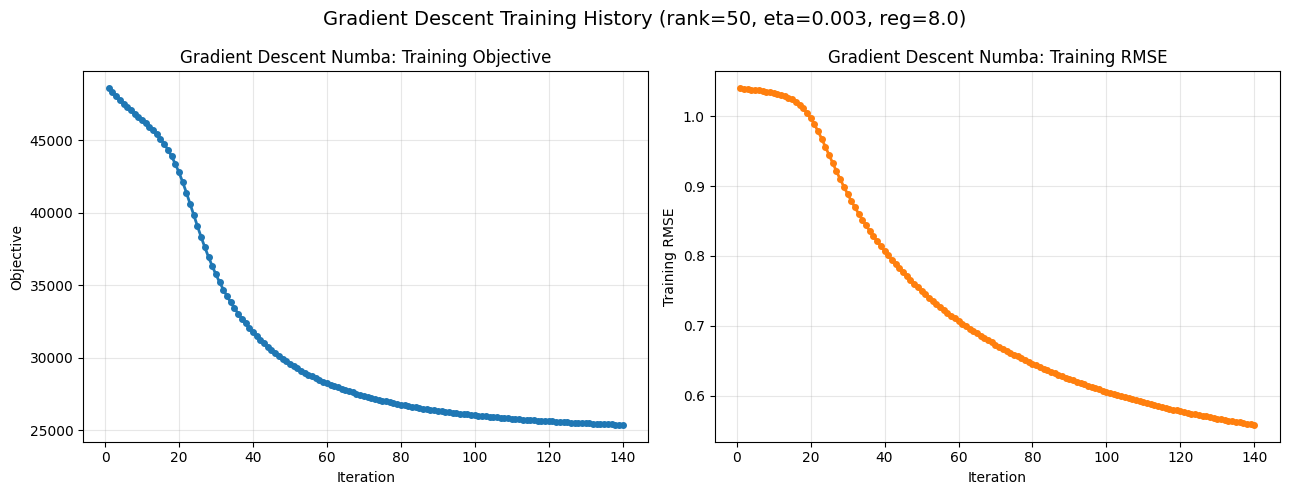

In [26]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

# Objective
axes[0].plot(
    gd_numba_history["iteration"],
    gd_numba_history["objective"],
    marker="o",
    markersize=4,
    linewidth=2,
)

axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Objective")
axes[0].set_title("Gradient Descent Numba: Training Objective")
axes[0].grid(True, alpha=0.3)

# Training RMSE
axes[1].plot(
    gd_numba_history["iteration"],
    gd_numba_history["train_rmse_raw"],
    marker="o",
    markersize=4,
    linewidth=2,
    color="tab:orange",
)

axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Training RMSE")
axes[1].set_title("Gradient Descent Numba: Training RMSE")
axes[1].grid(True, alpha=0.3)

fig.suptitle(
    f"Gradient Descent Training History "
    f"(rank={best_gd_numba_rank}, "
    f"eta={best_gd_numba_eta}, "
    f"reg={best_gd_numba_reg})",
    fontsize=14,
)

plt.tight_layout()
plt.show()

## ALS

### Parameter search

In [18]:
val_user_idx = val_df["user_idx"].to_numpy(dtype=np.int64)
val_movie_idx = val_df["movie_idx"].to_numpy(dtype=np.int64)
val_ratings = val_df["rating"].to_numpy(dtype=np.float64)


def validation_metrics_als_numba(U, V, global_mean):
    predictions = (
        global_mean
        + np.sum(
            U[val_user_idx] * V[val_movie_idx],
            axis=1,
        )
    )
    predictions = np.clip(predictions, 0.5, 5.0)

    return {
        "val_rmse": rmse_from_predictions(
            val_ratings,
            predictions,
        ),
        "val_mae": mae_from_predictions(
            val_ratings,
            predictions,
        ),
    }

In [19]:
als_numba_rank_values = [2, 5, 10]
als_numba_reg_values = [4.0, 6.0, 8.0, 10.0, 12.0]

als_numba_init_scale = 0.01
als_numba_histories = []

for rank in als_numba_rank_values:
    for reg in als_numba_reg_values:
        print(
            f"Training ALS Numba: "
            f"rank={rank}, reg={reg}"
        )

        U, V, global_mean, history_df = als_model_numba(
            train_fit_df,
            n_users=n_users,
            n_movies=n_movies,
            rank=rank,
            reg=reg,
            n_iter=60,
            init_scale=als_numba_init_scale,
            random_state=42,
            metrics_fn=validation_metrics_als_numba,
            parallel=True,
            min_iter=5,
            objective_tol=1e-6,
            patience=5,
        )

        als_numba_histories.append(history_df)

als_numba_tuning_results_df = pd.concat(
    als_numba_histories,
    ignore_index=True,
)

Training ALS Numba: rank=2, reg=4.0
Training ALS Numba: rank=2, reg=6.0
Training ALS Numba: rank=2, reg=8.0
Training ALS Numba: rank=2, reg=10.0
Training ALS Numba: rank=2, reg=12.0
Training ALS Numba: rank=5, reg=4.0
Training ALS Numba: rank=5, reg=6.0
Training ALS Numba: rank=5, reg=8.0
Training ALS Numba: rank=5, reg=10.0
Training ALS Numba: rank=5, reg=12.0
Training ALS Numba: rank=10, reg=4.0
Training ALS Numba: rank=10, reg=6.0
Training ALS Numba: rank=10, reg=8.0
Training ALS Numba: rank=10, reg=10.0
Training ALS Numba: rank=10, reg=12.0


In [20]:
als_numba_best_by_config = (
    als_numba_tuning_results_df.loc[
        als_numba_tuning_results_df
        .groupby(["rank", "reg"])["val_rmse"]
        .idxmin()
    ]
    .sort_values("val_rmse")
)

display(als_numba_best_by_config)

,iteration,rank,reg,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse,val_mae
22,23,2,4.0,22740.548689,0.757609,0.757466,1.553326e-06,0.895218,0.691201
45,16,2,6.0,24598.132850,0.780299,0.780134,5.457193e-07,0.897887,0.695480
58,10,2,8.0,26091.987748,0.800369,0.800187,8.428809e-06,0.902783,0.701233
276,60,5,8.0,24310.537546,0.723998,0.723732,9.848939e-06,0.906225,0.703114
216,60,5,6.0,22256.441939,0.689820,0.689493,1.023989e-05,0.907047,0.700530
336,60,5,10.0,25987.745060,0.753847,0.753635,1.272340e-05,0.908216,0.706273
79,14,2,10.0,27337.051673,0.818384,0.818197,8.732261e-08,0.908826,0.707613
630,54,10,10.0,25024.619219,0.695285,0.695166,1.017221e-05,0.910834,0.706597
693,57,10,12.0,26733.932237,0.735073,0.734991,9.416029e-06,0.911694,0.708810
396,60,5,12.0,27390.993309,0.780767,0.780608,6.156980e-06,0.912892,0.710896


In [21]:
refined_als_rank_values = [1, 2, 3, 4]
refined_als_reg_values = [2.0, 3.0, 4.0, 5.0, 6.0]

als_numba_refined_histories = []

for rank in refined_als_rank_values:
    for reg in refined_als_reg_values:
        print(
            f"Training refined ALS Numba: "
            f"rank={rank}, reg={reg}"
        )

        U, V, global_mean, history_df = als_model_numba(
            train_fit_df,
            n_users=n_users,
            n_movies=n_movies,
            rank=rank,
            reg=reg,
            n_iter=60,
            init_scale=0.01,
            random_state=42,
            metrics_fn=validation_metrics_als_numba,
            parallel=True,
            min_iter=5,
            objective_tol=1e-6,
            patience=5,
        )

        als_numba_refined_histories.append(history_df)

als_numba_refined_results_df = pd.concat(
    als_numba_refined_histories,
    ignore_index=True,
)

Training refined ALS Numba: rank=1, reg=2.0
Training refined ALS Numba: rank=1, reg=3.0
Training refined ALS Numba: rank=1, reg=4.0
Training refined ALS Numba: rank=1, reg=5.0
Training refined ALS Numba: rank=1, reg=6.0
Training refined ALS Numba: rank=2, reg=2.0
Training refined ALS Numba: rank=2, reg=3.0
Training refined ALS Numba: rank=2, reg=4.0
Training refined ALS Numba: rank=2, reg=5.0
Training refined ALS Numba: rank=2, reg=6.0
Training refined ALS Numba: rank=3, reg=2.0
Training refined ALS Numba: rank=3, reg=3.0
Training refined ALS Numba: rank=3, reg=4.0
Training refined ALS Numba: rank=3, reg=5.0
Training refined ALS Numba: rank=3, reg=6.0
Training refined ALS Numba: rank=4, reg=2.0
Training refined ALS Numba: rank=4, reg=3.0
Training refined ALS Numba: rank=4, reg=4.0
Training refined ALS Numba: rank=4, reg=5.0
Training refined ALS Numba: rank=4, reg=6.0


In [22]:
als_numba_refined_best_by_config = (
    als_numba_refined_results_df.loc[
        als_numba_refined_results_df
        .groupby(["rank", "reg"])["val_rmse"]
        .idxmin()
    ]
    .sort_values("val_rmse")
)

display(als_numba_refined_best_by_config)

,iteration,rank,reg,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse,val_mae
290,23,2,4.0,22740.548689,0.757609,0.757466,1.553326e-06,0.895218,0.691201
267,34,2,3.0,21601.344982,0.744875,0.744746,4.225590e-07,0.895681,0.690000
319,22,2,5.0,23724.405688,0.769260,0.769108,2.620320e-07,0.896120,0.693049
335,16,2,6.0,24598.132850,0.780299,0.780134,5.457193e-07,0.897887,0.695480
192,7,2,2.0,20308.509098,0.732911,0.732797,2.420004e-03,0.898282,0.689863
630,52,3,6.0,23613.808492,0.744138,0.743892,9.335460e-06,0.900665,0.696108
578,60,3,5.0,22599.628557,0.730127,0.729885,6.173035e-06,0.900959,0.695032
518,60,3,4.0,21445.417383,0.715063,0.714827,4.098127e-06,0.902954,0.695088
938,60,4,6.0,22875.402015,0.715390,0.715085,5.489869e-05,0.905176,0.699037
458,60,3,3.0,20110.442717,0.699043,0.698804,1.330875e-05,0.907487,0.696385


### Full training and test sets

In [23]:
best_als_numba_rank = 2
best_als_numba_reg = 4.0
best_als_numba_init_scale = 0.01
best_als_numba_n_iter = 23

U_als_numba, V_als_numba, als_global_mean, als_numba_history = (
    als_model_numba(
        train_df,
        n_users=n_users,
        n_movies=n_movies,
        rank=best_als_numba_rank,
        reg=best_als_numba_reg,
        n_iter=best_als_numba_n_iter,
        init_scale=best_als_numba_init_scale,
        random_state=42,
        parallel=True,
    )
)

In [24]:
test_user_idx = test_df["user_idx"].to_numpy(dtype=np.int64)
test_movie_idx = test_df["movie_idx"].to_numpy(dtype=np.int64)
test_ratings = test_df["rating"].to_numpy(dtype=np.float64)

als_test_predictions = (
    als_global_mean
    + np.sum(
        U_als_numba[test_user_idx]
        * V_als_numba[test_movie_idx],
        axis=1,
    )
)

als_test_predictions = np.clip(
    als_test_predictions,
    0.5,
    5.0,
)

als_numba_test_rmse = rmse_from_predictions(
    test_ratings,
    als_test_predictions,
)
als_numba_test_mae = mae_from_predictions(
    test_ratings,
    als_test_predictions,
)

print("Final ALS Numba rank:", best_als_numba_rank)
print("Final ALS Numba reg:", best_als_numba_reg)
print("Final ALS Numba init_scale:", best_als_numba_init_scale)
print("Final ALS Numba n_iter:", best_als_numba_n_iter)
print("ALS Numba test RMSE:", als_numba_test_rmse)
print("ALS Numba test MAE:", als_numba_test_mae)

Final ALS Numba rank: 2
Final ALS Numba reg: 4.0
Final ALS Numba init_scale: 0.01
Final ALS Numba n_iter: 23
ALS Numba test RMSE: 0.8965515139968124
ALS Numba test MAE: 0.6867641937441624


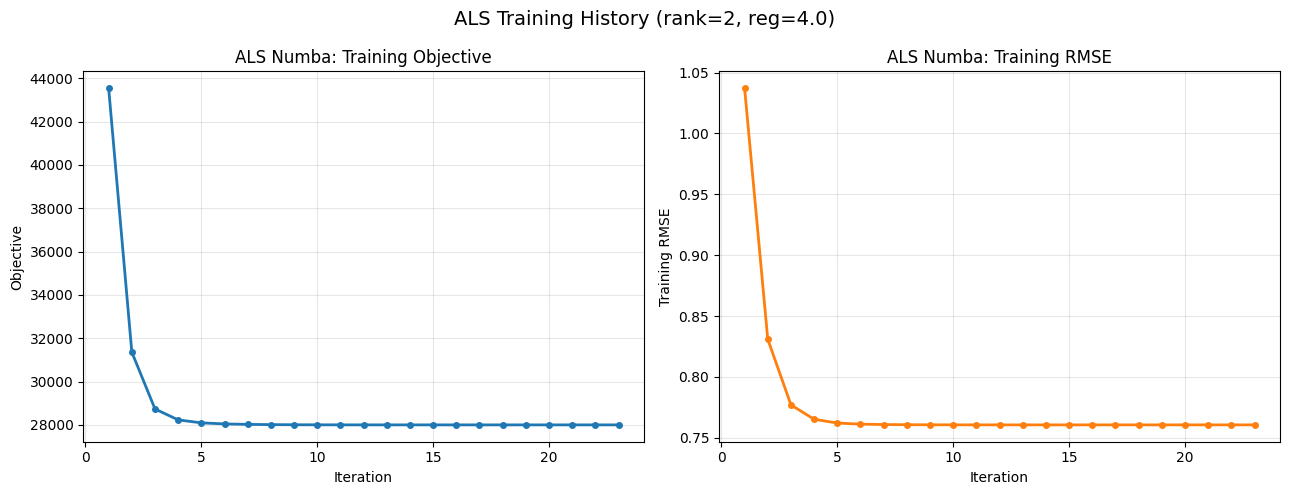

In [25]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

# Objective
axes[0].plot(
    als_numba_history["iteration"],
    als_numba_history["objective"],
    marker="o",
    markersize=4,
    linewidth=2,
)

axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Objective")
axes[0].set_title("ALS Numba: Training Objective")
axes[0].grid(True, alpha=0.3)

# Training RMSE
axes[1].plot(
    als_numba_history["iteration"],
    als_numba_history["train_rmse"],
    marker="o",
    markersize=4,
    linewidth=2,
    color="tab:orange",
)

axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Training RMSE")
axes[1].set_title("ALS Numba: Training RMSE")
axes[1].grid(True, alpha=0.3)

fig.suptitle(
    f"ALS Training History "
    f"(rank={best_als_numba_rank}, "
    f"reg={best_als_numba_reg})",
    fontsize=14,
)

plt.tight_layout()
plt.show()

## SGD


### Parameter tuning

In [31]:
def validation_metrics_sgd_numba(U, V, global_mean):
    predictions = (
        global_mean
        + np.sum(U[val_user_idx] * V[val_movie_idx], axis=1)
    )
    predictions = np.clip(predictions, 0.5, 5.0)

    return {
        "val_rmse": rmse_from_predictions(val_ratings, predictions),
        "val_mae": mae_from_predictions(val_ratings, predictions),
    }

sgd_rank_values = [20, 40, 60]
sgd_eta_values = [0.005, 0.01, 0.015]
sgd_reg_values = [6.0, 8.0, 10.0]
sgd_init_scale_values = [0.005, 0.01]

sgd_numba_histories = []


config_number = 0

for rank in sgd_rank_values:
    for eta in sgd_eta_values:
        for reg in sgd_reg_values:
            for init_scale in sgd_init_scale_values:
                config_number += 1

                print(
                    f"rank={rank}, eta={eta}, reg={reg}, "
                    f"init_scale={init_scale}"
                )

                _, _, _, history_df = sgd_numba(
                    train_fit_df,
                    n_users=n_users,
                    n_movies=n_movies,
                    rank=rank,
                    eta=eta,
                    reg=reg,
                    n_iter=80,
                    init_scale=init_scale,
                    random_state=42,
                    metrics_fn=validation_metrics_sgd_numba,
                )

                sgd_numba_histories.append(history_df)

sgd_numba_tuning_results_df = pd.concat(
    sgd_numba_histories,
    ignore_index=True,
)

rank=20, eta=0.005, reg=6.0, init_scale=0.005
rank=20, eta=0.005, reg=6.0, init_scale=0.01
rank=20, eta=0.005, reg=8.0, init_scale=0.005
rank=20, eta=0.005, reg=8.0, init_scale=0.01
rank=20, eta=0.005, reg=10.0, init_scale=0.005
rank=20, eta=0.005, reg=10.0, init_scale=0.01
rank=20, eta=0.01, reg=6.0, init_scale=0.005
rank=20, eta=0.01, reg=6.0, init_scale=0.01
rank=20, eta=0.01, reg=8.0, init_scale=0.005
rank=20, eta=0.01, reg=8.0, init_scale=0.01
rank=20, eta=0.01, reg=10.0, init_scale=0.005
rank=20, eta=0.01, reg=10.0, init_scale=0.01
rank=20, eta=0.015, reg=6.0, init_scale=0.005
rank=20, eta=0.015, reg=6.0, init_scale=0.01
rank=20, eta=0.015, reg=8.0, init_scale=0.005
rank=20, eta=0.015, reg=8.0, init_scale=0.01
rank=20, eta=0.015, reg=10.0, init_scale=0.005
rank=20, eta=0.015, reg=10.0, init_scale=0.01
rank=40, eta=0.005, reg=6.0, init_scale=0.005
rank=40, eta=0.005, reg=6.0, init_scale=0.01
rank=40, eta=0.005, reg=8.0, init_scale=0.005
rank=40, eta=0.005, reg=8.0, init_scale=0.01

In [32]:
config_columns = ["rank", "eta", "reg", "init_scale"]

sgd_numba_best_by_config = (
    sgd_numba_tuning_results_df.loc[
        sgd_numba_tuning_results_df
        .groupby(config_columns)["val_rmse"]
        .idxmin()
    ]
    .sort_values("val_rmse")
)

display(sgd_numba_best_by_config.head(15))

,iteration,steps,rank,eta,reg,init_scale,objective,average_objective,train_rmse_raw,train_rmse,val_rmse,val_mae
2956,77,4969118,60,0.005,6.0,0.005,20396.085277,0.316052,0.639932,0.639828,0.894803,0.693118
3865,26,1677884,60,0.015,6.0,0.005,20534.920268,0.318203,0.640039,0.639903,0.895636,0.693834
3399,40,2581360,60,0.010,6.0,0.005,20304.509668,0.314633,0.631014,0.630891,0.895978,0.694068
1517,78,5033652,40,0.005,6.0,0.005,20674.208405,0.320361,0.651793,0.651672,0.896150,0.693513
3036,77,4969118,60,0.005,6.0,0.010,19721.524477,0.305599,0.603556,0.603469,0.896193,0.694424
1588,69,4452846,40,0.005,6.0,0.010,20631.067596,0.319693,0.651867,0.651745,0.896578,0.693996
1958,39,2516826,40,0.010,6.0,0.005,20773.812308,0.321905,0.652882,0.652749,0.896675,0.693533
3943,24,1548816,60,0.015,6.0,0.010,20248.044573,0.313758,0.626569,0.626451,0.896822,0.694508
3476,37,2387758,60,0.010,6.0,0.010,20016.593483,0.310171,0.616815,0.616706,0.896828,0.694472
2427,28,1806952,40,0.015,6.0,0.005,20507.650618,0.317781,0.635115,0.634939,0.896920,0.694248


In [33]:
sgd_rank_values = [50, 60, 80]
sgd_eta_values = [0.004, 0.005, 0.0075, 0.01]
sgd_reg_values = [4.0, 5.0, 6.0]
sgd_init_scale_values = [0.003, 0.005]

sgd_numba_refined_histories = []

total_configs = (
    len(sgd_rank_values)
    * len(sgd_eta_values)
    * len(sgd_reg_values)
    * len(sgd_init_scale_values)
)

config_number = 0

for rank in sgd_rank_values:
    for eta in sgd_eta_values:
        for reg in sgd_reg_values:
            for init_scale in sgd_init_scale_values:
                config_number += 1

                print(
                    f"[{config_number}/{total_configs}] "
                    f"rank={rank}, eta={eta}, reg={reg}, "
                    f"init_scale={init_scale}"
                )

                _, _, _, history_df = sgd_numba(
                    train_fit_df,
                    n_users=n_users,
                    n_movies=n_movies,
                    rank=rank,
                    eta=eta,
                    reg=reg,
                    n_iter=120,
                    init_scale=init_scale,
                    random_state=42,
                    metrics_fn=validation_metrics_sgd_numba,
                )

                sgd_numba_refined_histories.append(history_df)

sgd_numba_refined_results_df = pd.concat(
    sgd_numba_refined_histories,
    ignore_index=True,
)

[1/72] rank=50, eta=0.004, reg=4.0, init_scale=0.003
[2/72] rank=50, eta=0.004, reg=4.0, init_scale=0.005
[3/72] rank=50, eta=0.004, reg=5.0, init_scale=0.003
[4/72] rank=50, eta=0.004, reg=5.0, init_scale=0.005
[5/72] rank=50, eta=0.004, reg=6.0, init_scale=0.003
[6/72] rank=50, eta=0.004, reg=6.0, init_scale=0.005
[7/72] rank=50, eta=0.005, reg=4.0, init_scale=0.003
[8/72] rank=50, eta=0.005, reg=4.0, init_scale=0.005
[9/72] rank=50, eta=0.005, reg=5.0, init_scale=0.003
[10/72] rank=50, eta=0.005, reg=5.0, init_scale=0.005
[11/72] rank=50, eta=0.005, reg=6.0, init_scale=0.003
[12/72] rank=50, eta=0.005, reg=6.0, init_scale=0.005
[13/72] rank=50, eta=0.0075, reg=4.0, init_scale=0.003
[14/72] rank=50, eta=0.0075, reg=4.0, init_scale=0.005
[15/72] rank=50, eta=0.0075, reg=5.0, init_scale=0.003
[16/72] rank=50, eta=0.0075, reg=5.0, init_scale=0.005
[17/72] rank=50, eta=0.0075, reg=6.0, init_scale=0.003
[18/72] rank=50, eta=0.0075, reg=6.0, init_scale=0.005
[19/72] rank=50, eta=0.01, reg=

In [34]:
config_columns = ["rank", "eta", "reg", "init_scale"]

sgd_numba_refined_best_by_config = (
    sgd_numba_refined_results_df.loc[
        sgd_numba_refined_results_df
        .groupby(config_columns)["val_rmse"]
        .idxmin()
    ]
    .sort_values("val_rmse")
)

display(sgd_numba_refined_best_by_config.head(15))

,iteration,steps,rank,eta,reg,init_scale,objective,average_objective,train_rmse_raw,train_rmse,val_rmse,val_mae
7248,49,3162166,80,0.0075,4.0,0.003,17403.709458,0.269683,0.604217,0.604050,0.889781,0.687367
6550,71,4581914,80,0.0050,4.0,0.003,17650.483735,0.273507,0.616193,0.616039,0.889907,0.687324
6669,70,4517380,80,0.0050,4.0,0.005,16982.368141,0.263154,0.588736,0.588583,0.890043,0.687930
5850,91,5872594,80,0.0040,4.0,0.003,17409.167595,0.269767,0.606498,0.606349,0.890082,0.687373
5963,84,5420856,80,0.0040,4.0,0.005,17295.584375,0.268007,0.603578,0.603442,0.890092,0.687346
7368,49,3162166,80,0.0075,4.0,0.005,16653.940150,0.258065,0.571624,0.571463,0.890351,0.687830
7608,49,3162166,80,0.0075,5.0,0.005,18693.158934,0.289664,0.609235,0.609120,0.890989,0.688956
6910,71,4581914,80,0.0050,5.0,0.005,18866.527749,0.292350,0.619522,0.619412,0.891024,0.688957
7488,49,3162166,80,0.0075,5.0,0.003,19343.083134,0.299735,0.638444,0.638319,0.891037,0.689028
8072,33,2129622,80,0.0100,4.0,0.005,17562.236492,0.272139,0.612213,0.612033,0.891084,0.688548


### Training and test sets

In [35]:
best_sgd_rank = 80
best_sgd_eta = 0.0075
best_sgd_reg = 4.0
best_sgd_init_scale = 0.003
best_sgd_n_iter = 49

sgd_U, sgd_V, sgd_global_mean, sgd_history_df = sgd_numba(
    train_df,
    n_users=n_users,
    n_movies=n_movies,
    rank=best_sgd_rank,
    eta=best_sgd_eta,
    reg=best_sgd_reg,
    n_iter=best_sgd_n_iter,
    init_scale=best_sgd_init_scale,
    random_state=42,
)

In [36]:
test_user_idx = test_df["user_idx"].to_numpy(dtype=np.int64)
test_movie_idx = test_df["movie_idx"].to_numpy(dtype=np.int64)
test_ratings = test_df["rating"].to_numpy(dtype=np.float64)

sgd_test_predictions = (
    sgd_global_mean
    + np.sum(
        sgd_U[test_user_idx] * sgd_V[test_movie_idx],
        axis=1,
    )
)

sgd_test_predictions = np.clip(sgd_test_predictions, 0.5, 5.0)

sgd_test_rmse = rmse_from_predictions(
    test_ratings,
    sgd_test_predictions,
)

sgd_test_mae = mae_from_predictions(
    test_ratings,
    sgd_test_predictions,
)

print(f"SGD test RMSE: {sgd_test_rmse:.6f}")
print(f"SGD test MAE:  {sgd_test_mae:.6f}")

SGD test RMSE: 0.892508
SGD test MAE:  0.681769


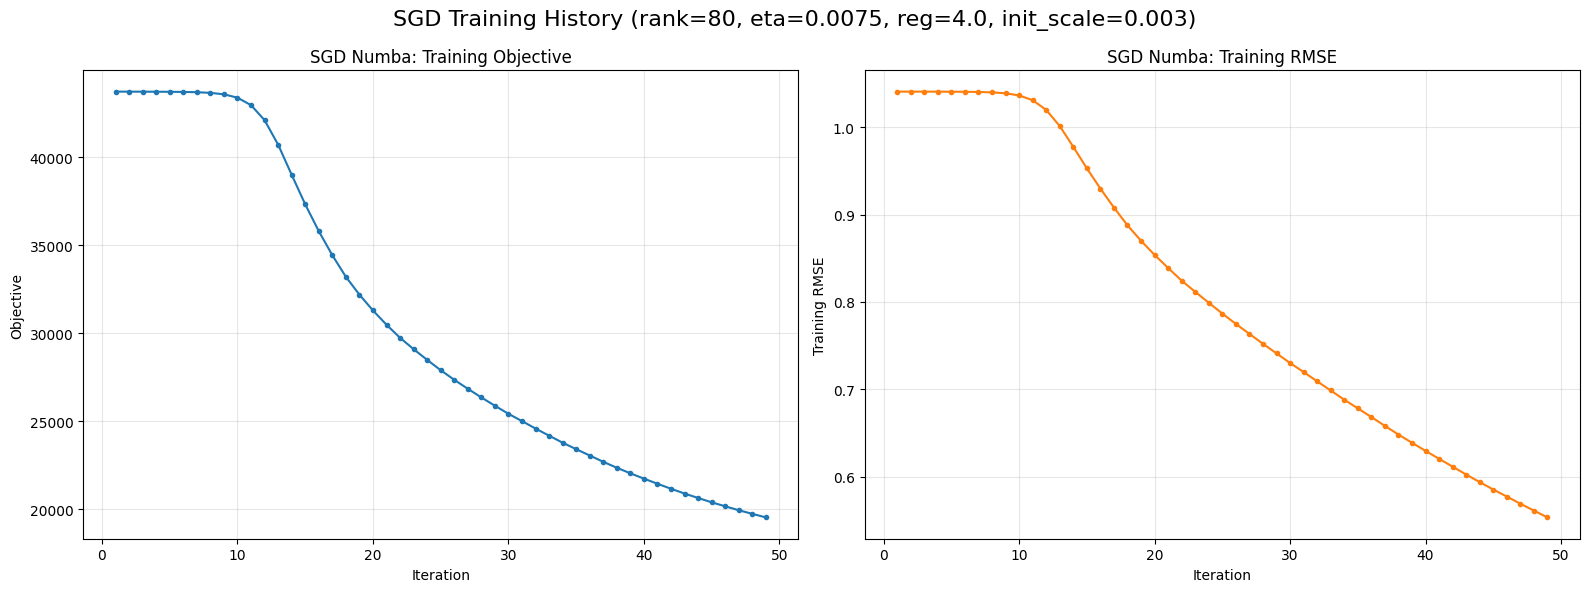

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(
    "SGD Training History "
    f"(rank={best_sgd_rank}, eta={best_sgd_eta}, "
    f"reg={best_sgd_reg}, init_scale={best_sgd_init_scale})",
    fontsize=16,
)

axes[0].plot(
    sgd_history_df["iteration"],
    sgd_history_df["objective"],
    marker="o",
    markersize=3,
)

axes[0].set_title("SGD Numba: Training Objective")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Objective")
axes[0].grid(alpha=0.3)

axes[1].plot(
    sgd_history_df["iteration"],
    sgd_history_df["train_rmse"],
    marker="o",
    markersize=3,
    color="tab:orange",
)

axes[1].set_title("SGD Numba: Training RMSE")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Training RMSE")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Comparison of models

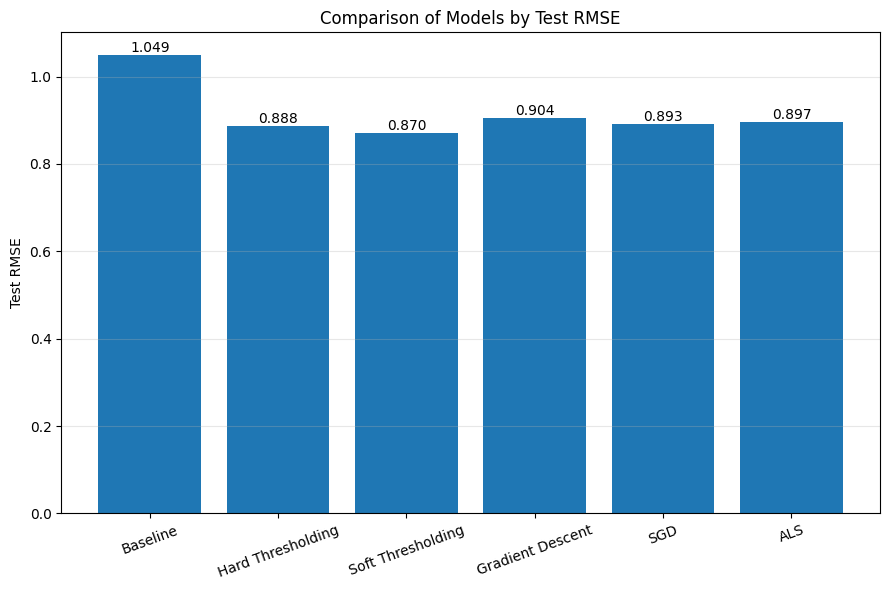

In [43]:
model_names = [
    "Baseline",
    "Hard Thresholding",
    "Soft Thresholding",
    "Gradient Descent",
    "SGD",
    "ALS",
]

test_rmse_values = [
    baseline_test_rmse,
    hard_test_rmse,
    soft_test_rmse,
    gd_numba_test_rmse,
    sgd_test_rmse,
    als_numba_test_rmse,
]

plt.figure(figsize=(9, 6))

bars = plt.bar(model_names, test_rmse_values)

plt.ylabel("Test RMSE")
plt.title("Comparison of Models by Test RMSE")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha="center",
        va="bottom",
    )

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

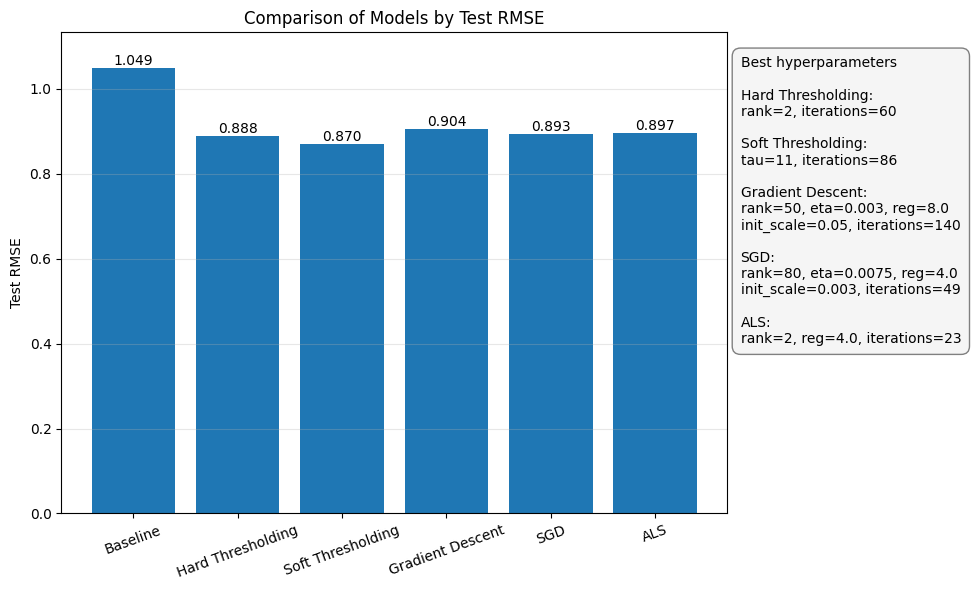

In [46]:
model_names = [
    "Baseline",
    "Hard Thresholding",
    "Soft Thresholding",
    "Gradient Descent",
    "SGD",
    "ALS",
]

test_rmse_values = [
    baseline_test_rmse,
    hard_test_rmse,
    soft_test_rmse,
    gd_numba_test_rmse,
    sgd_test_rmse,
    als_numba_test_rmse,
]

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.bar(model_names, test_rmse_values)

ax.set_ylabel("Test RMSE")
ax.set_title("Comparison of Models by Test RMSE")
ax.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha="center",
        va="bottom",
    )

ax.tick_params(axis="x", rotation=20)
ax.set_ylim(0, max(test_rmse_values) * 1.08)

parameters_text = (
    "Best hyperparameters\n\n"
    "Hard Thresholding:\n"
    "rank=2, iterations=60\n\n"
    "Soft Thresholding:\n"
    "tau=11, iterations=86\n\n"
    "Gradient Descent:\n"
    "rank=50, eta=0.003, reg=8.0\n"
    "init_scale=0.05, iterations=140\n\n"
    "SGD:\n"
    "rank=80, eta=0.0075, reg=4.0\n"
    "init_scale=0.003, iterations=49\n\n"
    "ALS:\n"
    "rank=2, reg=4.0, iterations=23"
)

ax.text(
    1.02,
    0.95,
    parameters_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    bbox={
        "boxstyle": "round,pad=0.6",
        "facecolor": "whitesmoke",
        "edgecolor": "gray",
    },
)

plt.tight_layout(rect=[0, 0, 0.76, 1])
plt.show()

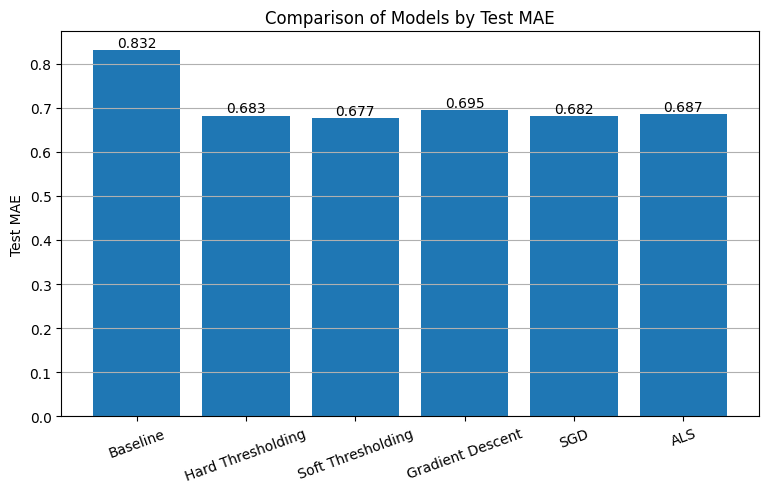

In [44]:
test_mae_values = [
    baseline_test_mae,
    hard_test_mae,
    soft_test_mae,
    gd_numba_test_mae,
    sgd_test_mae,
    als_numba_test_mae,
]

plt.figure(figsize=(9, 5))

bars = plt.bar(model_names, test_mae_values)

plt.ylabel("Test MAE")
plt.title("Comparison of Models by Test MAE")
plt.grid(axis="y")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=20)
plt.show()

Both RMSE and MAE show that Soft Thresholding achieved the best test performance. Hard Thresholding also improved clearly over the baseline. The Gradient Descent matrix factorization model did not outperform the baseline, which suggests that this simple full-batch implementation without bias terms is less effective for this dataset.